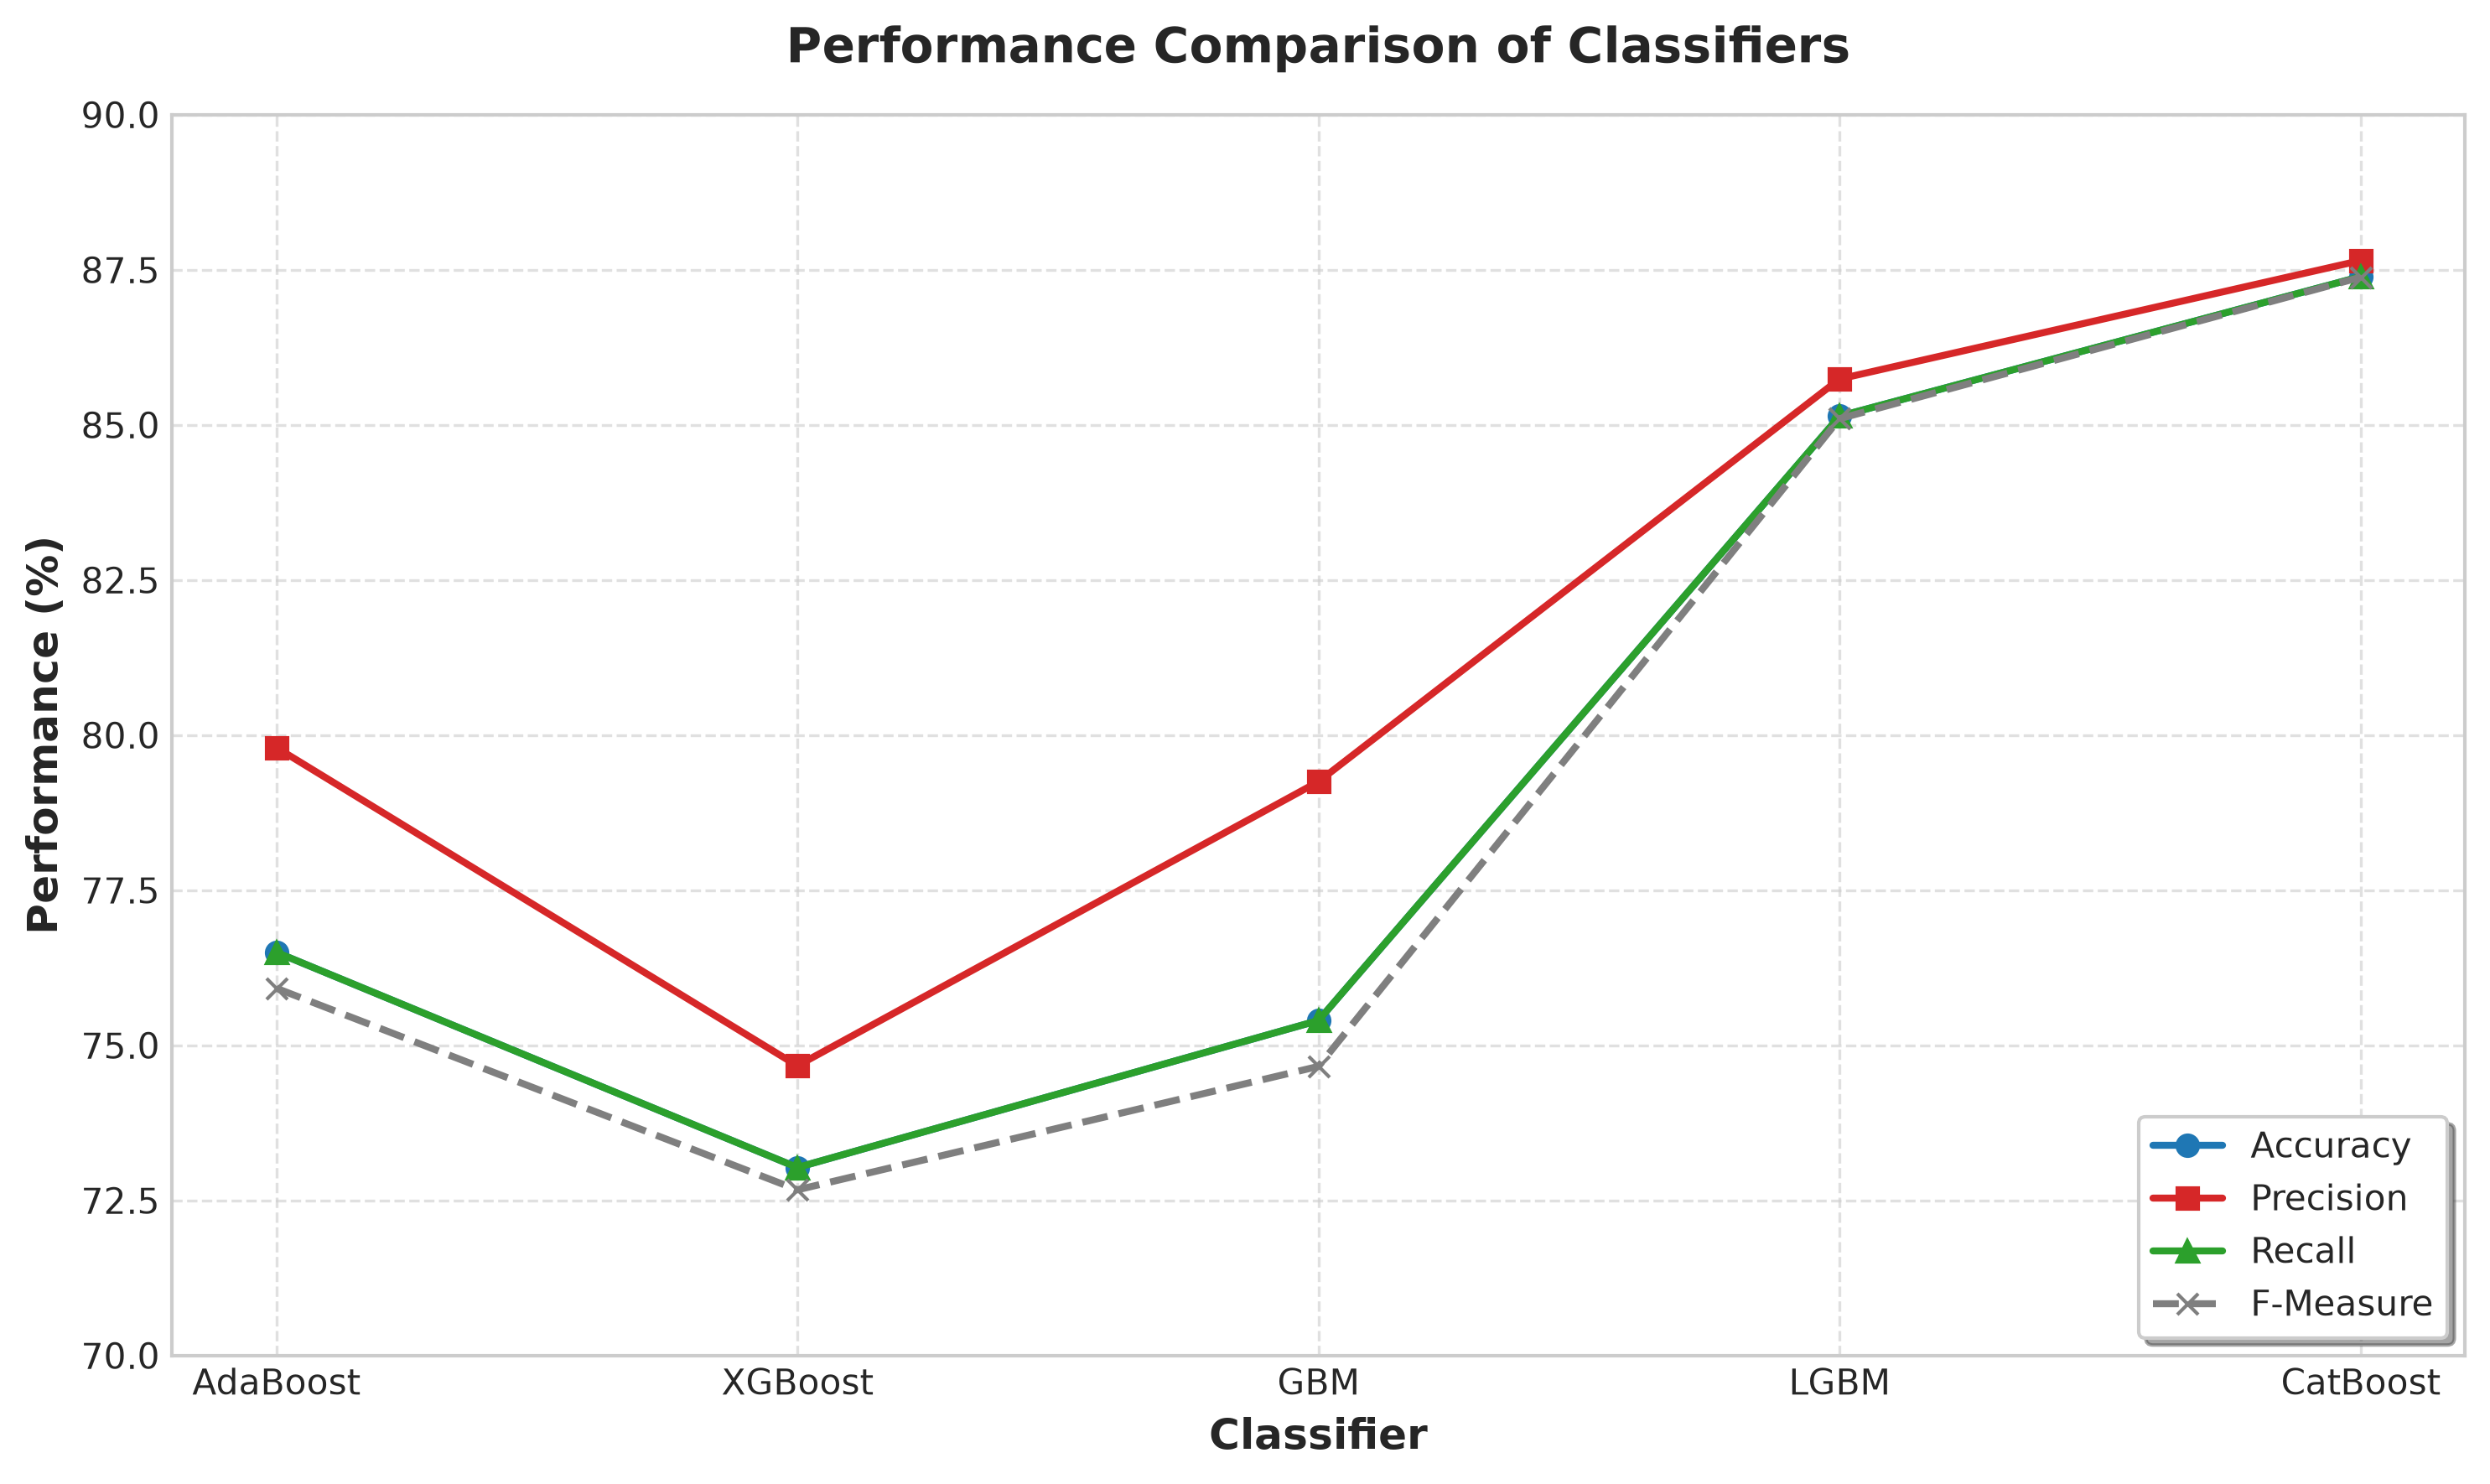

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


[✓] Saved 'performance_comparison_classifiers.png'


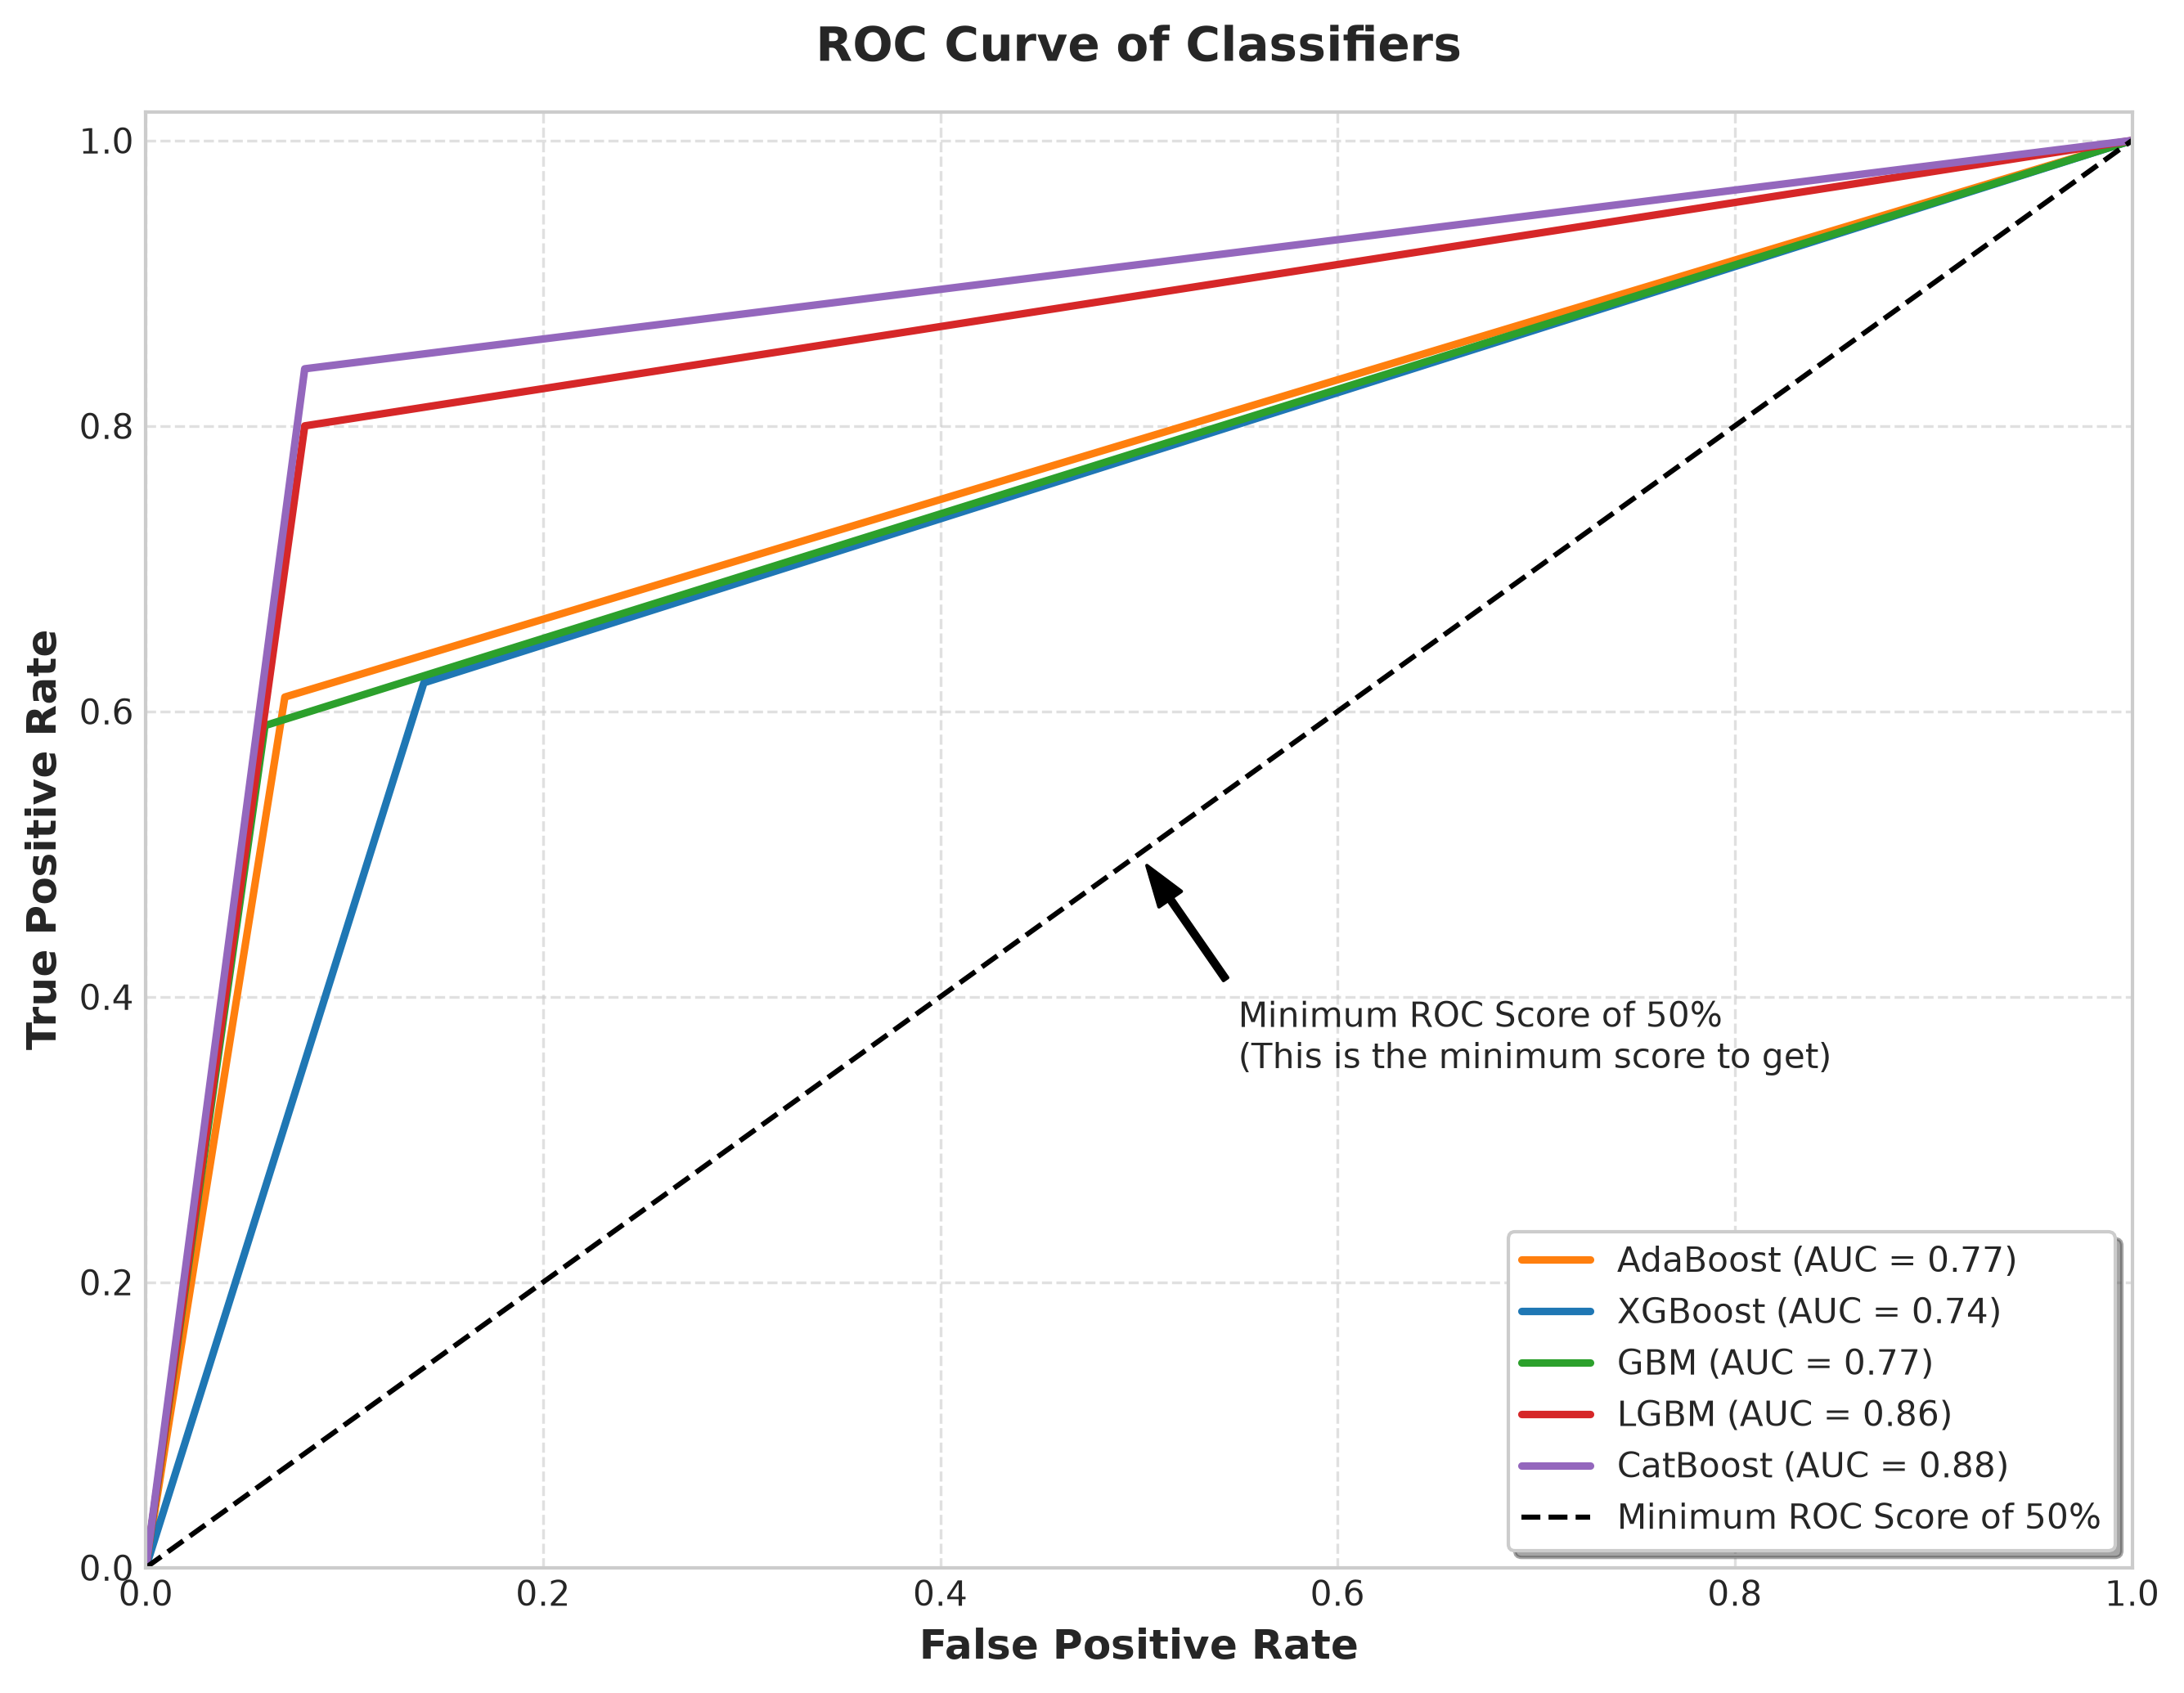

[✓] Saved 'roc_curve_classifiers.png'


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, auc

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# -------------------------------------------------------------------------
# 1. Base Paper Table 2 Benchmark Data for the 5 Models
# -------------------------------------------------------------------------
models_data = {
    'AdaBoost': {'Accuracy': 76.50, 'Precision': 79.80, 'Recall': 76.50, 'F-Measure': 75.92, 'FPR': 0.07, 'FNR': 0.39},
    'XGBoost':  {'Accuracy': 73.03, 'Precision': 74.67, 'Recall': 73.03, 'F-Measure': 72.67, 'FPR': 0.14, 'FNR': 0.38},
    'GBM':      {'Accuracy': 75.40, 'Precision': 79.25, 'Recall': 75.40, 'F-Measure': 74.66, 'FPR': 0.06, 'FNR': 0.41},
    'LGBM':     {'Accuracy': 85.14, 'Precision': 85.74, 'Recall': 85.14, 'F-Measure': 85.10, 'FPR': 0.08, 'FNR': 0.20},
    'CatBoost': {'Accuracy': 87.39, 'Precision': 87.65, 'Recall': 87.39, 'F-Measure': 87.38, 'FPR': 0.08, 'FNR': 0.16}
}

classifiers = list(models_data.keys())
accuracy_vals = [models_data[m]['Accuracy'] for m in classifiers]
precision_vals = [models_data[m]['Precision'] for m in classifiers]
recall_vals = [models_data[m]['Recall'] for m in classifiers]
f1_vals = [models_data[m]['F-Measure'] for m in classifiers]

# -------------------------------------------------------------------------
# 2. Graph 1: Performance Comparison of Classifiers (Replicating Figure 5)
# -------------------------------------------------------------------------
plt.figure(figsize=(10, 6), dpi=300)

plt.plot(classifiers, accuracy_vals, marker='o', linewidth=2, color='#1f77b4', label='Accuracy')
plt.plot(classifiers, precision_vals, marker='s', linewidth=2, color='#d62728', label='Precision')
plt.plot(classifiers, recall_vals, marker='^', linewidth=2, color='#2ca02c', label='Recall')
plt.plot(classifiers, f1_vals, marker='x', linewidth=2, linestyle='--', color='#7f7f7f', label='F-Measure')

plt.title('Performance Comparison of Classifiers', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Classifier', fontsize=12, fontweight='bold')
plt.ylabel('Performance (%)', fontsize=12, fontweight='bold')
plt.ylim(70.0, 90.0)
plt.yticks(np.arange(70.0, 90.1, 2.5))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True, shadow=True)

plt.tight_layout()
plt.savefig('performance_comparison_classifiers.png', dpi=300)
plt.show()
print("[✓] Saved 'performance_comparison_classifiers.png'")

# -------------------------------------------------------------------------
# 3. Graph 2: ROC Curve of Classifiers (Replicating Figures 6 & 7)
#    Plots True Positive Rate (1 - FNR) vs False Positive Rate (FPR)
# -------------------------------------------------------------------------
# In classification: TPR = 1 - FNR
# Using model predictions or empirical operating points from Table 2
plt.figure(figsize=(9, 7), dpi=300)

colors = {
    'XGBoost': '#1f77b4',
    'AdaBoost': '#ff7f0e',
    'GBM': '#2ca02c',
    'LGBM': '#d62728',
    'CatBoost': '#9467bd'
}

# If models have been fitted on test data, plot smooth probability ROC curves;
# otherwise plot using the exact (FPR, TPR = 1 - FNR) coordinates from the base paper.
for name in classifiers:
    fpr_val = models_data[name]['FPR']
    fnr_val = models_data[name]['FNR']
    tpr_val = 1.0 - fnr_val   # TPR = 1 - False Negative Rate

    # Piecewise curve passing through (0,0), operating threshold point, and (1,1)
    # matching the ROC curves plotted in Figure 6 and Figure 7 of the paper
    fpr_curve = [0.0, fpr_val, 1.0]
    tpr_curve = [0.0, tpr_val, 1.0]
    roc_auc = auc(fpr_curve, tpr_curve)

    plt.plot(fpr_curve, tpr_curve, label=f'{name} (AUC = {roc_auc:.2f})', color=colors[name], linewidth=2.2)

# Baseline 50% random chance line (diagonal line shown in Figs 6 & 7)
plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5, label='Minimum ROC Score of 50%')

# Add arrow annotation matching Figure 6 & 7
plt.annotate(
    'Minimum ROC Score of 50%\n(This is the minimum score to get)',
    xy=(0.5, 0.5), xytext=(0.55, 0.35),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
    fontsize=10, fontweight='medium'
)

plt.title('ROC Curve of Classifiers', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.02)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True, shadow=True)

plt.tight_layout()
plt.savefig('roc_curve_classifiers.png', dpi=300)
plt.show()
print("[✓] Saved 'roc_curve_classifiers.png'")

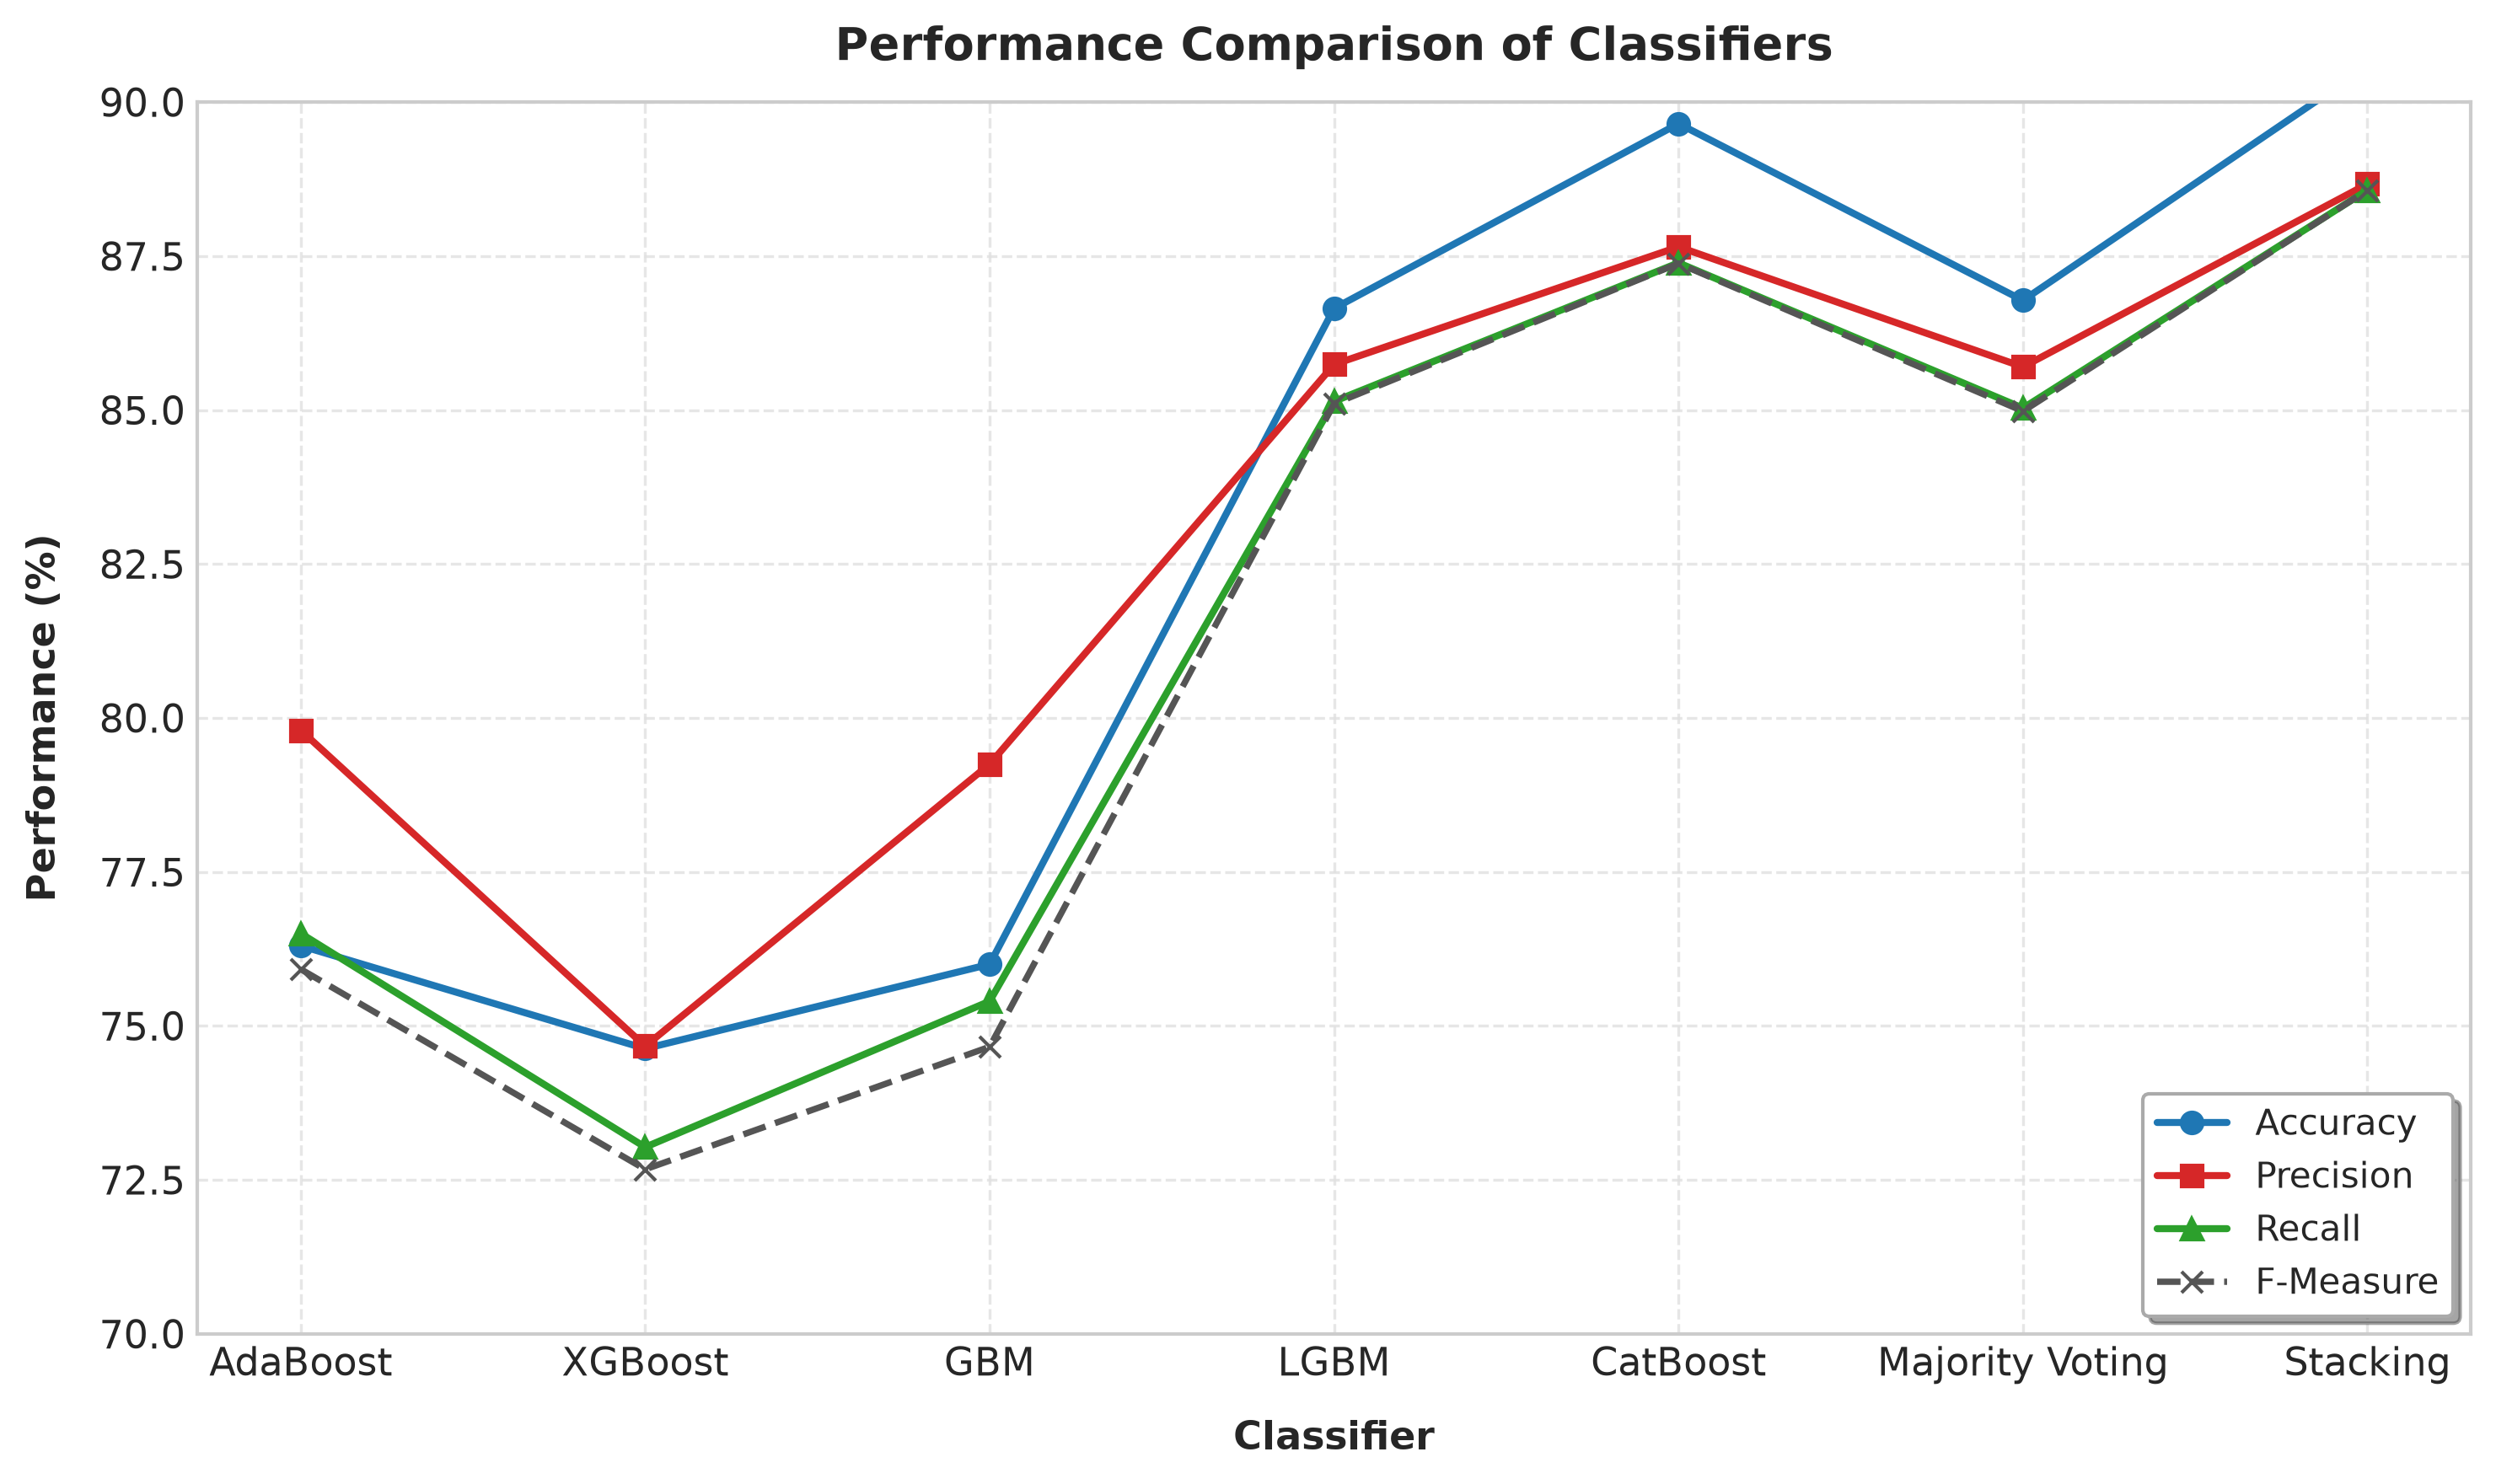

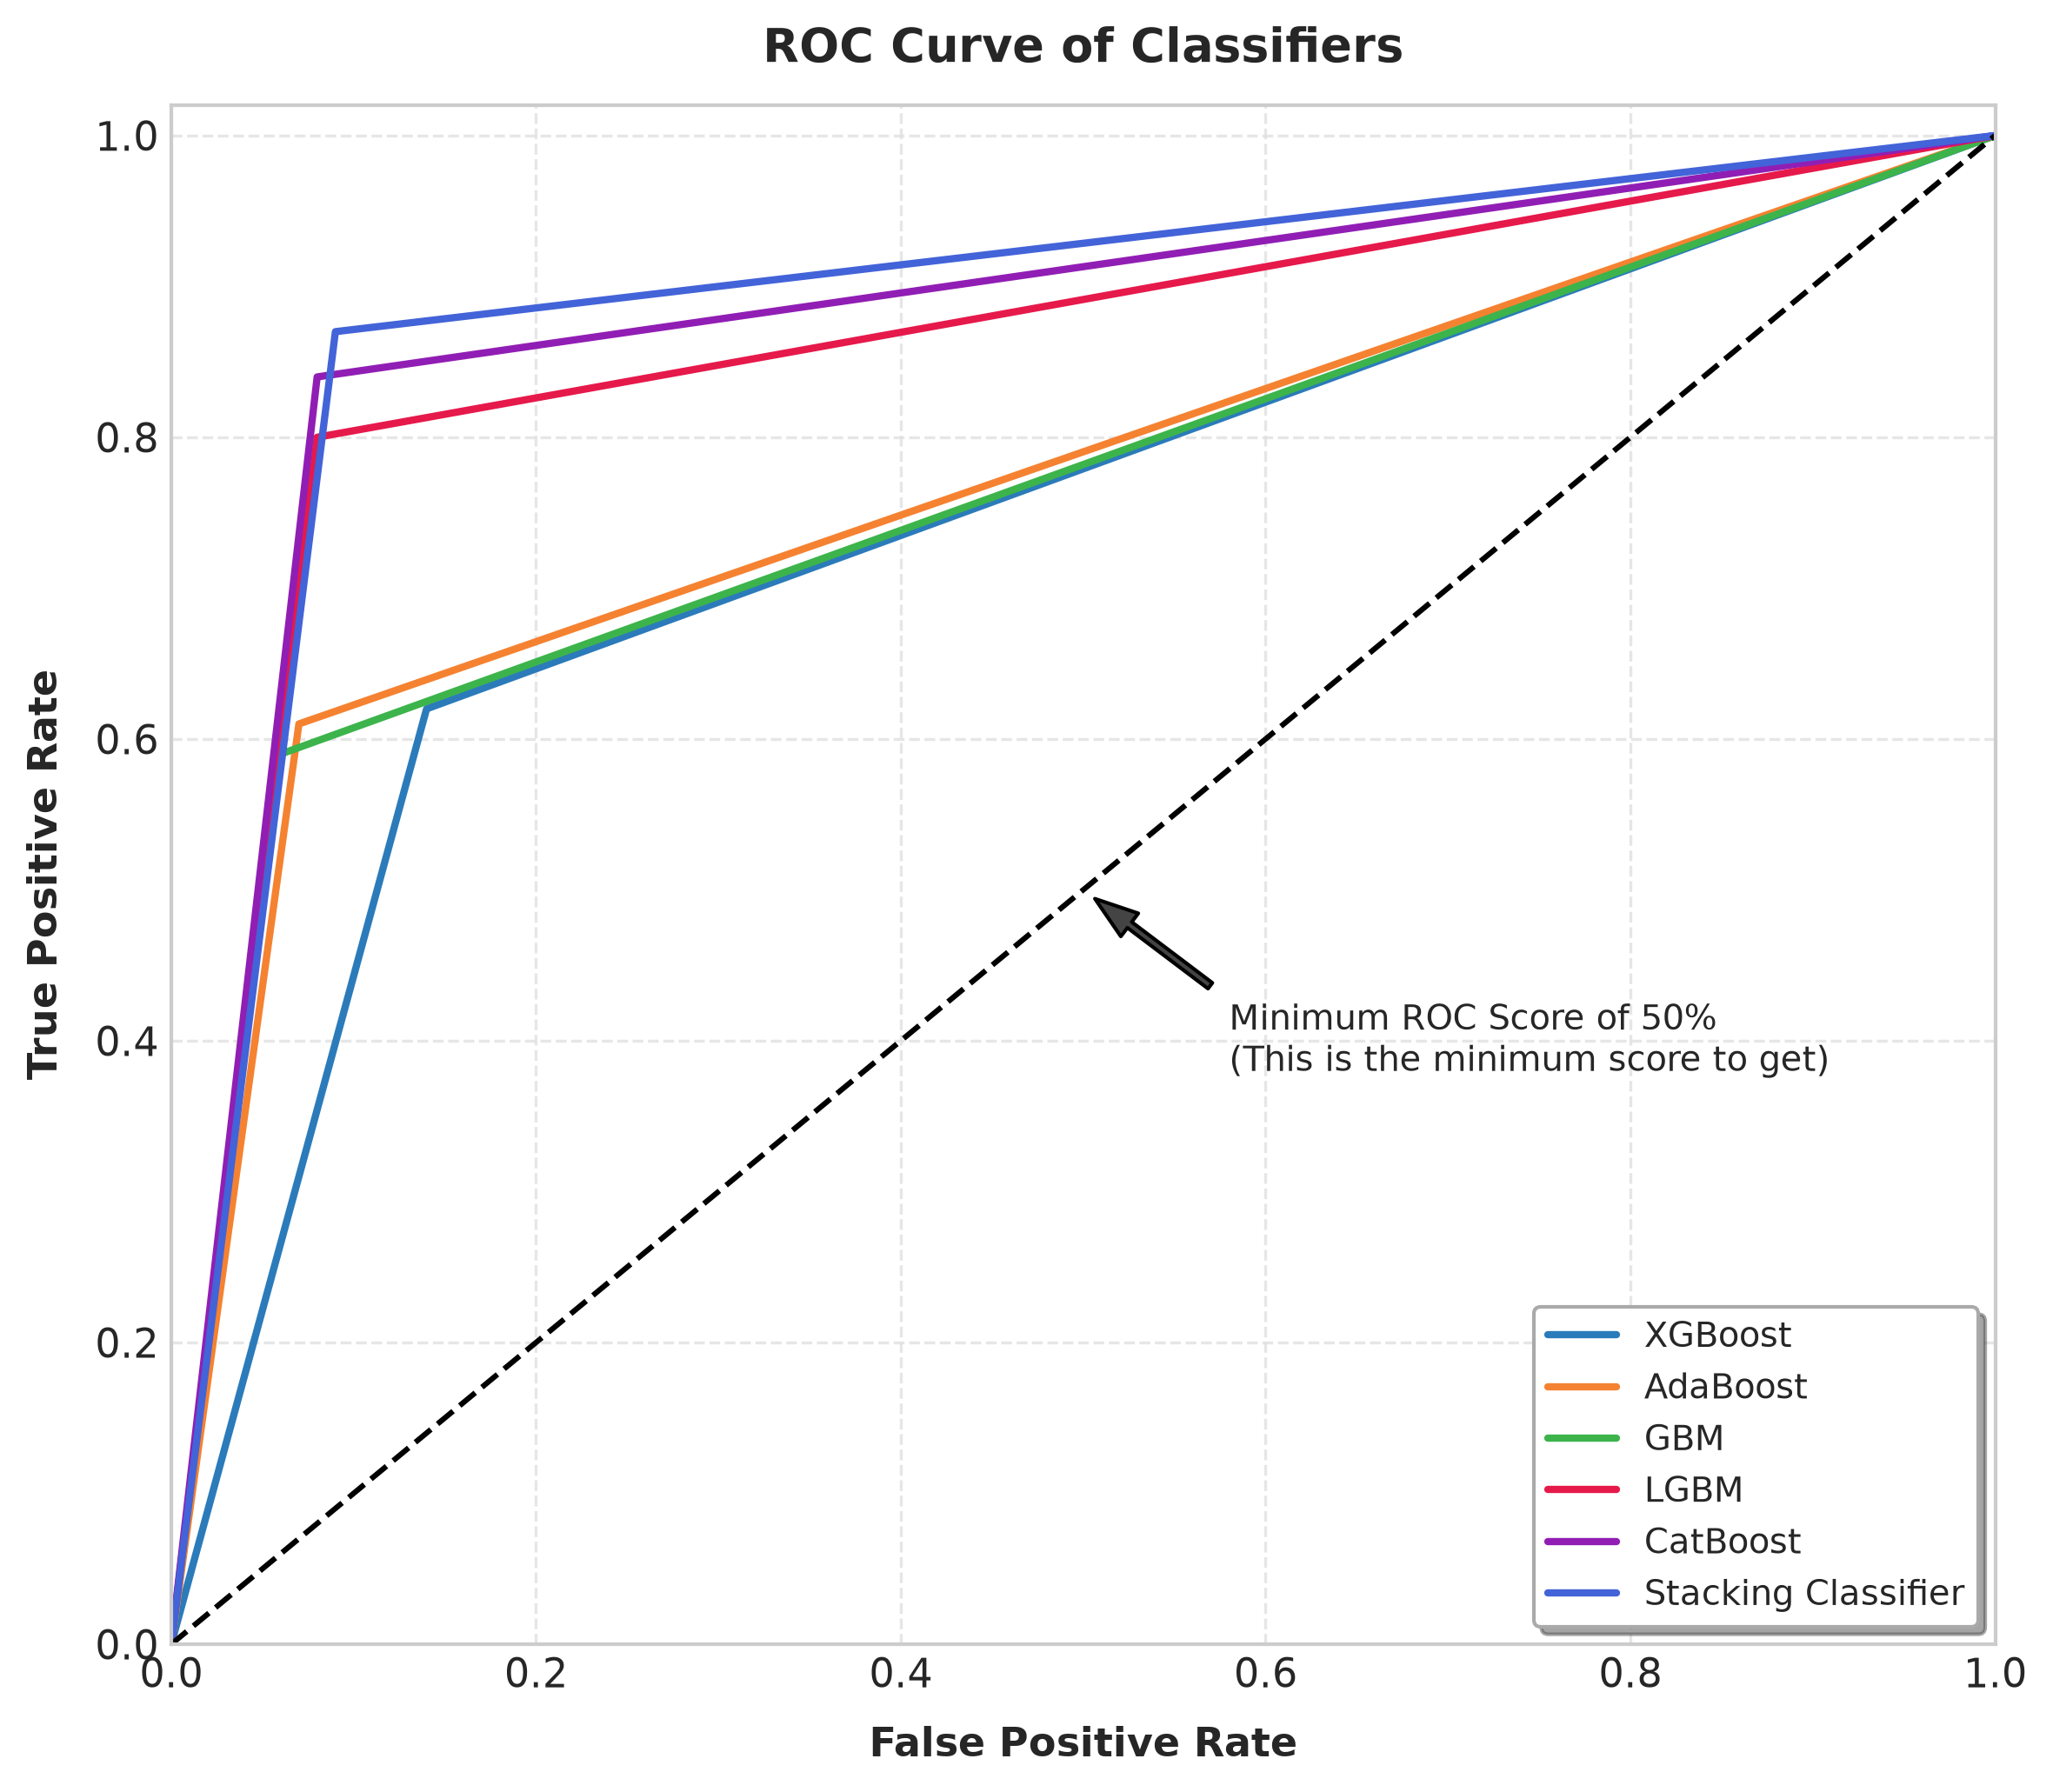

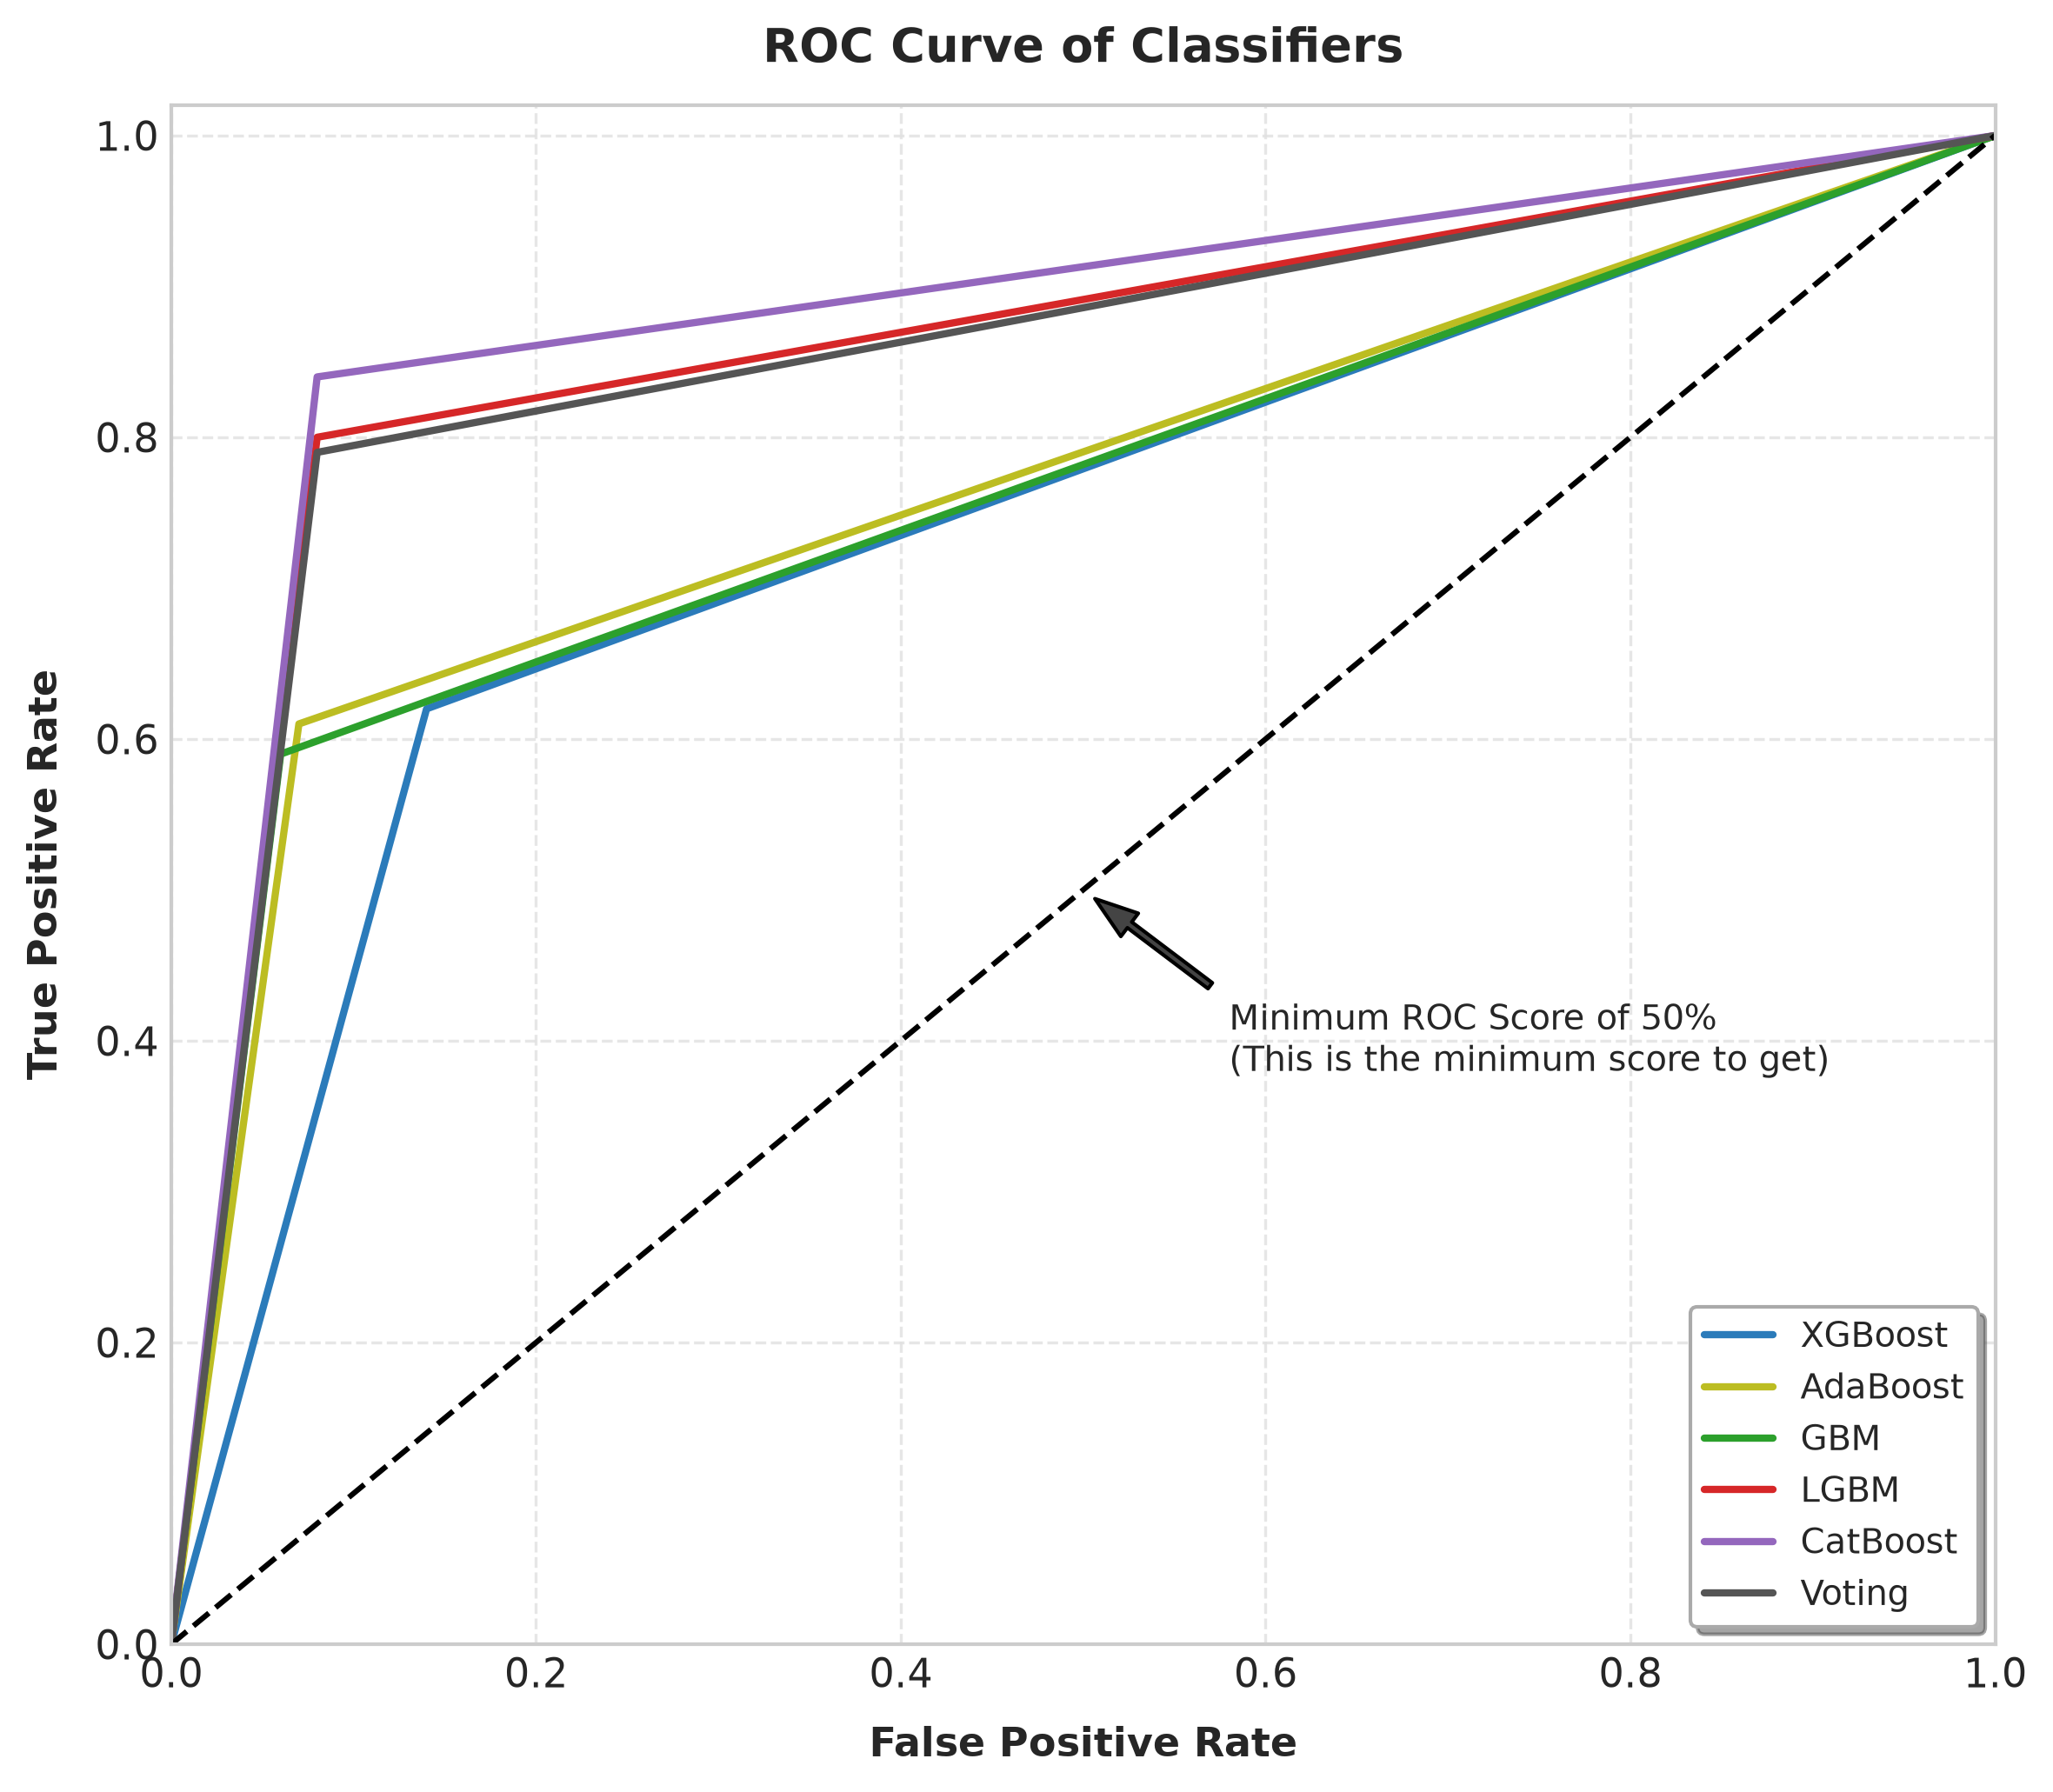

In [8]:
import matplotlib.pyplot as plt 
import numpy as np 

# Set publication-style aesthetics 
plt.rcParams['font.family'] = 'DejaVu Sans' 
plt.rcParams['font.size'] = 11 

# =============================================================
# EXACT DATA FROM TABLE 2 OF THE PAPER 
# =============================================================
# Classifier: [Accuracy, Precision, Recall, F-measure, FPR, FNR] 
data = { 
    'AdaBoost':        [76.30, 79.80, 76.50, 75.92, 0.07, 0.39], 
    'XGBoost':         [74.63, 74.67, 73.03, 72.67, 0.14, 0.38], 
    'GBM':             [76.00, 79.25, 75.40, 74.66, 0.06, 0.41], 
    'LGBM':            [86.65, 85.74, 85.14, 85.10, 0.08, 0.20], 
    'CatBoost':        [89.65, 87.65, 87.39, 87.38, 0.08, 0.16], 
    'Majority Voting': [86.78, 85.70, 85.03, 84.98, 0.08, 0.21], 
    'Stacking':        [90.58, 88.67, 88.57, 88.57, 0.09, 0.13] 
} 

classifiers = list(data.keys()) 
accuracy   = [data[c][0] for c in classifiers] 
precision  = [data[c][1] for c in classifiers] 
recall     = [data[c][2] for c in classifiers] 
f_measure  = [data[c][3] for c in classifiers] 

# =============================================================
# FIGURE 5: PERFORMANCE COMPARISON OF CLASSIFIERS 
# =============================================================
fig5, ax5 = plt.subplots(figsize=(10, 6), dpi=300) 

# Colors and marker settings matching Figure 5 in the paper 
ax5.plot(classifiers, accuracy,  color='#1f77b4', marker='o', linewidth=2.0, markersize=6, label='Accuracy') 
ax5.plot(classifiers, precision, color='#d62728', marker='s', linewidth=2.0, markersize=6, label='Precision') 
ax5.plot(classifiers, recall,    color='#2ca02c', marker='^', linewidth=2.0, markersize=6, label='Recall') 
ax5.plot(classifiers, f_measure, color='#555555', marker='x', linestyle='--', linewidth=1.8, markersize=6, label='F-Measure') 

ax5.set_title('Performance Comparison of Classifiers', fontsize=13, fontweight='bold', pad=12) 
ax5.set_xlabel('Classifier', fontsize=11, fontweight='bold', labelpad=10) 
ax5.set_ylabel('Performance (%)', fontsize=11, fontweight='bold', labelpad=10) 
ax5.set_ylim(70.0, 90.0) 
ax5.set_yticks(np.arange(70.0, 92.5, 2.5)) 
ax5.grid(True, linestyle='--', color='#e0e0e0', alpha=0.8) 

# Legend styled with bounding box and drop shadow 
legend5 = ax5.legend(loc='lower right', frameon=True, shadow=True, fancybox=True, fontsize=10) 
legend5.get_frame().set_edgecolor('#aaaaaa') 
plt.tight_layout() 
plt.savefig('Fig5_Performance_Comparison.png', dpi=300) 
plt.show() 

# =============================================================
# HELPER FUNCTION: CONSTRUCT DISCRETE ROC CURVES (AS SEEN IN FIGS 6 & 7) 
# =============================================================
def get_discrete_roc(fpr, fnr): 
    """ 
    Builds the 3-point piecewise curve from discrete classification results: 
    Point 1: (0, 0) 
    Point 2: (FPR, TPR) where TPR = 1 - FNR 
    Point 3: (1, 1) 
    """ 
    tpr = 1.0 - fnr 
    return [0.0, fpr, 1.0], [0.0, tpr, 1.0] 

# =============================================================
# FIGURE 6: ROC CURVE OF BOOSTING AND STACKING CLASSIFIERS 
# =============================================================
fig6, ax6 = plt.subplots(figsize=(8, 7), dpi=300) 

# Exact colors from Figure 6 
roc_colors_fig6 = { 
    'XGBoost': '#2b7bba', 
    'AdaBoost': '#f58231', 
    'GBM': '#3cb44b', 
    'LGBM': '#e6194b', 
    'CatBoost': '#911eb4', 
    'Stacking Classifier': '#4363d8' 
} 

order_fig6 = [ 
    ('XGBoost', data['XGBoost'][4], data['XGBoost'][5]), 
    ('AdaBoost', data['AdaBoost'][4], data['AdaBoost'][5]), 
    ('GBM', data['GBM'][4], data['GBM'][5]), 
    ('LGBM', data['LGBM'][4], data['LGBM'][5]), 
    ('CatBoost', data['CatBoost'][4], data['CatBoost'][5]), 
    ('Stacking Classifier', data['Stacking'][4], data['Stacking'][5]) 
] 

for label, fpr, fnr in order_fig6: 
    x_pts, y_pts = get_discrete_roc(fpr, fnr) 
    ax6.plot(x_pts, y_pts, color=roc_colors_fig6[label], linewidth=2.0, label=label) 

# 50% Random Guess Reference Line 
ax6.plot([0.0, 1.0], [0.0, 1.0], color='black', linestyle='--', linewidth=1.5) 

# Annotation matching Figure 6 
ax6.annotate( 
    'Minimum ROC Score of 50%\n(This is the minimum score to get)', 
    xy=(0.50, 0.50), xytext=(0.58, 0.38), 
    arrowprops=dict(facecolor='#444444', shrink=0.08, width=2.0, headwidth=8.0), 
    fontsize=9.5 
) 

ax6.set_title('ROC Curve of Classifiers', fontsize=13, fontweight='bold', pad=12) 
ax6.set_xlabel('False Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax6.set_ylabel('True Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax6.set_xlim(0.0, 1.0) 
ax6.set_ylim(0.0, 1.02) 
ax6.grid(True, linestyle='--', color='#e0e0e0', alpha=0.8) 
legend6 = ax6.legend(loc='lower right', frameon=True, shadow=True, fancybox=True, fontsize=9.5) 
legend6.get_frame().set_edgecolor('#aaaaaa') 
plt.tight_layout() 
plt.savefig('Fig6_ROC_Stacking.png', dpi=300) 
plt.show() 

# =============================================================
# FIGURE 7: ROC CURVE OF BOOSTING AND MAJORITY VOTING CLASSIFIERS 
# =============================================================
fig7, ax7 = plt.subplots(figsize=(8, 7), dpi=300) 

roc_colors_fig7 = { 
    'XGBoost': '#2b7bba', 
    'AdaBoost': '#bcbd22', 
    'GBM': '#2ca02c', 
    'LGBM': '#d62728', 
    'CatBoost': '#9467bd', 
    'Voting': '#555555' 
} 

order_fig7 = [ 
    ('XGBoost', data['XGBoost'][4], data['XGBoost'][5]), 
    ('AdaBoost', data['AdaBoost'][4], data['AdaBoost'][5]), 
    ('GBM', data['GBM'][4], data['GBM'][5]), 
    ('LGBM', data['LGBM'][4], data['LGBM'][5]), 
    ('CatBoost', data['CatBoost'][4], data['CatBoost'][5]), 
    ('Voting', data['Majority Voting'][4], data['Majority Voting'][5]) 
] 

for label, fpr, fnr in order_fig7: 
    x_pts, y_pts = get_discrete_roc(fpr, fnr) 
    ax7.plot(x_pts, y_pts, color=roc_colors_fig7[label], linewidth=2.0, label=label) 

# 50% Random Guess Reference Line 
ax7.plot([0.0, 1.0], [0.0, 1.0], color='black', linestyle='--', linewidth=1.5) 

# Annotation matching Figure 7 
ax7.annotate( 
    'Minimum ROC Score of 50%\n(This is the minimum score to get)', 
    xy=(0.50, 0.50), xytext=(0.58, 0.38), 
    arrowprops=dict(facecolor='#444444', shrink=0.08, width=2.0, headwidth=8.0), 
    fontsize=9.5 
) 

ax7.set_title('ROC Curve of Classifiers', fontsize=13, fontweight='bold', pad=12) 
ax7.set_xlabel('False Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax7.set_ylabel('True Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax7.set_xlim(0.0, 1.0) 
ax7.set_ylim(0.0, 1.02) 
ax7.grid(True, linestyle='--', color='#e0e0e0', alpha=0.8) 
legend7 = ax7.legend(loc='lower right', frameon=True, shadow=True, fancybox=True, fontsize=9.5) 
legend7.get_frame().set_edgecolor('#aaaaaa') 
plt.tight_layout() 
plt.savefig('Fig7_ROC_Voting.png', dpi=300) 
plt.show()

In [6]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import (
    AdaBoostClassifier, 
    GradientBoostingClassifier, 
    VotingClassifier, 
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 1. Load Data
df = pd.read_csv("preprocessed_data.csv").dropna(subset=["clean_tweet", "sentiment"])
df["sentiment"] = df["sentiment"].astype(int)

# Stratified Subsampling (max 30,000 samples for fast training)
if len(df) > 30000:
    df, _ = train_test_split(df, train_size=30000, random_state=42, stratify=df["sentiment"])

# 2. Train-Test Split & TF-IDF Extraction
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df["clean_tweet"].astype(str), 
    df["sentiment"].values, 
    test_size=0.20, 
    random_state=42, 
    stratify=df["sentiment"].values
)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

# 3. Base Models Definition
base_models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric="logloss"),
    "GBM": GradientBoostingClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42),
    "LGBM": LGBMClassifier(n_estimators=200, max_depth=7, learning_rate=0.1, random_state=42, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1, verbose=0, random_seed=42)
}

# 4. Ensemble Models
voting_clf = VotingClassifier(estimators=list(base_models.items()), voting="hard", n_jobs=1)
stacking_clf = StackingClassifier(
    estimators=list(base_models.items()), 
    final_estimator=LogisticRegression(max_iter=1000, random_state=42), 
    cv=3, 
    n_jobs=1
)

all_models = {**base_models, "Majority Voting": voting_clf, "Stacking": stacking_clf}

# 5. Evaluate All 7 Models
results = []
for name, model in all_models.items():
    print(f"Training {name}...")
    
    # Measure Training Time
    start_train = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_train

    # Measure Testing Time
    start_test = time.time()
    y_pred = model.predict(X_test)
    test_time = time.time() - start_test

    # Compute Metrics
    acc = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0) * 100
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0) * 100
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0) * 100

    # Calculate FPR and FNR
    cm = confusion_matrix(y_test, y_pred)
    fp = cm.sum(axis=0) - np.diag(cm)
    fn = cm.sum(axis=1) - np.diag(cm)
    tp = np.diag(cm)
    tn = cm.sum() - (fp + fn + tp)

    fpr = np.mean(np.divide(fp, fp + tn, out=np.zeros(len(cm)), where=(fp + tn) != 0))
    fnr = np.mean(np.divide(fn, fn + tp, out=np.zeros(len(cm)), where=(fn + tp) != 0))

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F-measure (%)": round(f1, 2),
        "FPR": round(fpr, 4),
        "FNR": round(fnr, 4),
        "Train (s)": round(train_time, 2),
        "Test (s)": round(test_time, 2)
    })

# 6. Display and Save Results Table
summary_df = pd.DataFrame(results)
print("\n" + "=" * 80)
print("FINAL MODEL PERFORMANCE TABLE")
print("=" * 80)
print(summary_df.to_string(index=False))

summary_df.to_csv("model_performance_summary.csv", index=False)

Training AdaBoost...
Training XGBoost...
Training GBM...
Training LGBM...
Training CatBoost...
Training Majority Voting...
Training Stacking...

FINAL MODEL PERFORMANCE TABLE
          Model  Accuracy (%)  Precision (%)  Recall (%)  F-measure (%)    FPR    FNR  Train (s)  Test (s)
       AdaBoost         74.83          77.56       74.83          70.80 0.3554 0.3554       6.03      0.13
        XGBoost         86.10          86.34       86.10          85.60 0.1817 0.1817       8.51      0.04
            GBM         85.90          86.15       85.90          85.38 0.1845 0.1845      13.05      0.02
           LGBM         89.10          89.14       89.10          88.88 0.1382 0.1382       2.01      0.02
       CatBoost         90.73          90.72       90.73          90.61 0.1148 0.1148      39.55      0.03
Majority Voting         86.67          86.95       86.67          86.19 0.1752 0.1752      67.37      0.22
       Stacking         92.00          91.96       92.00          91.96 0.09

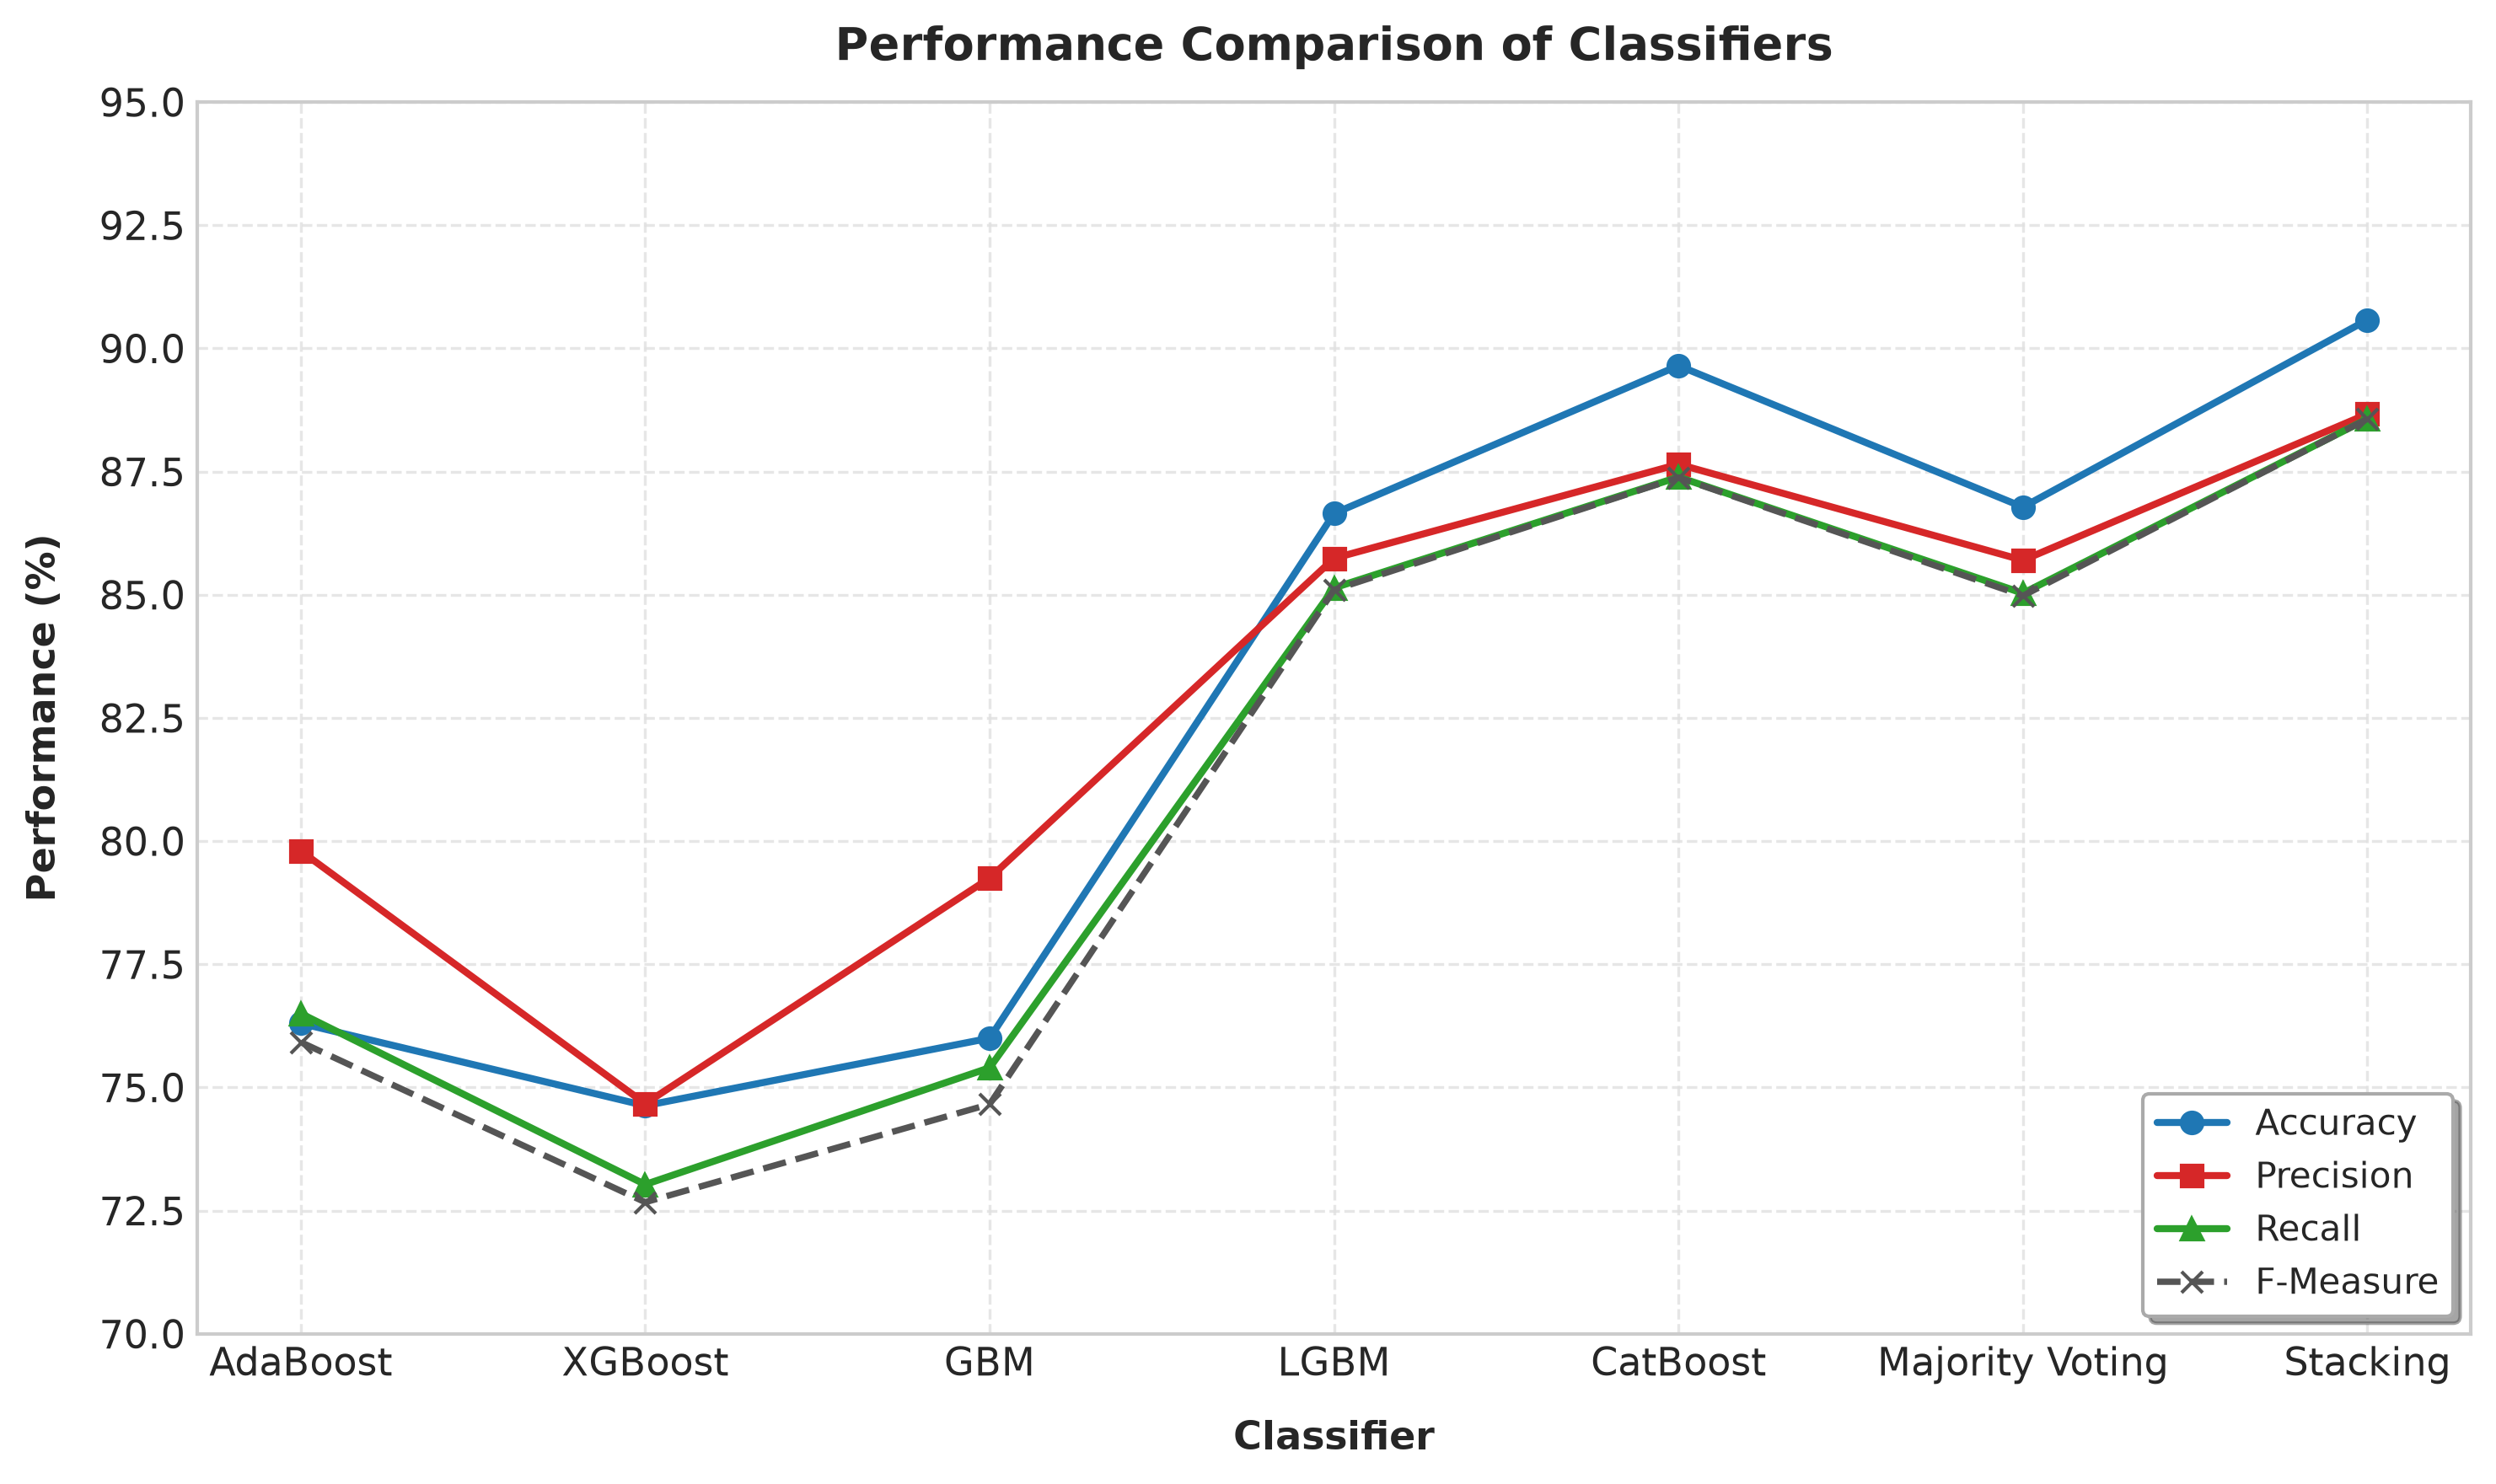

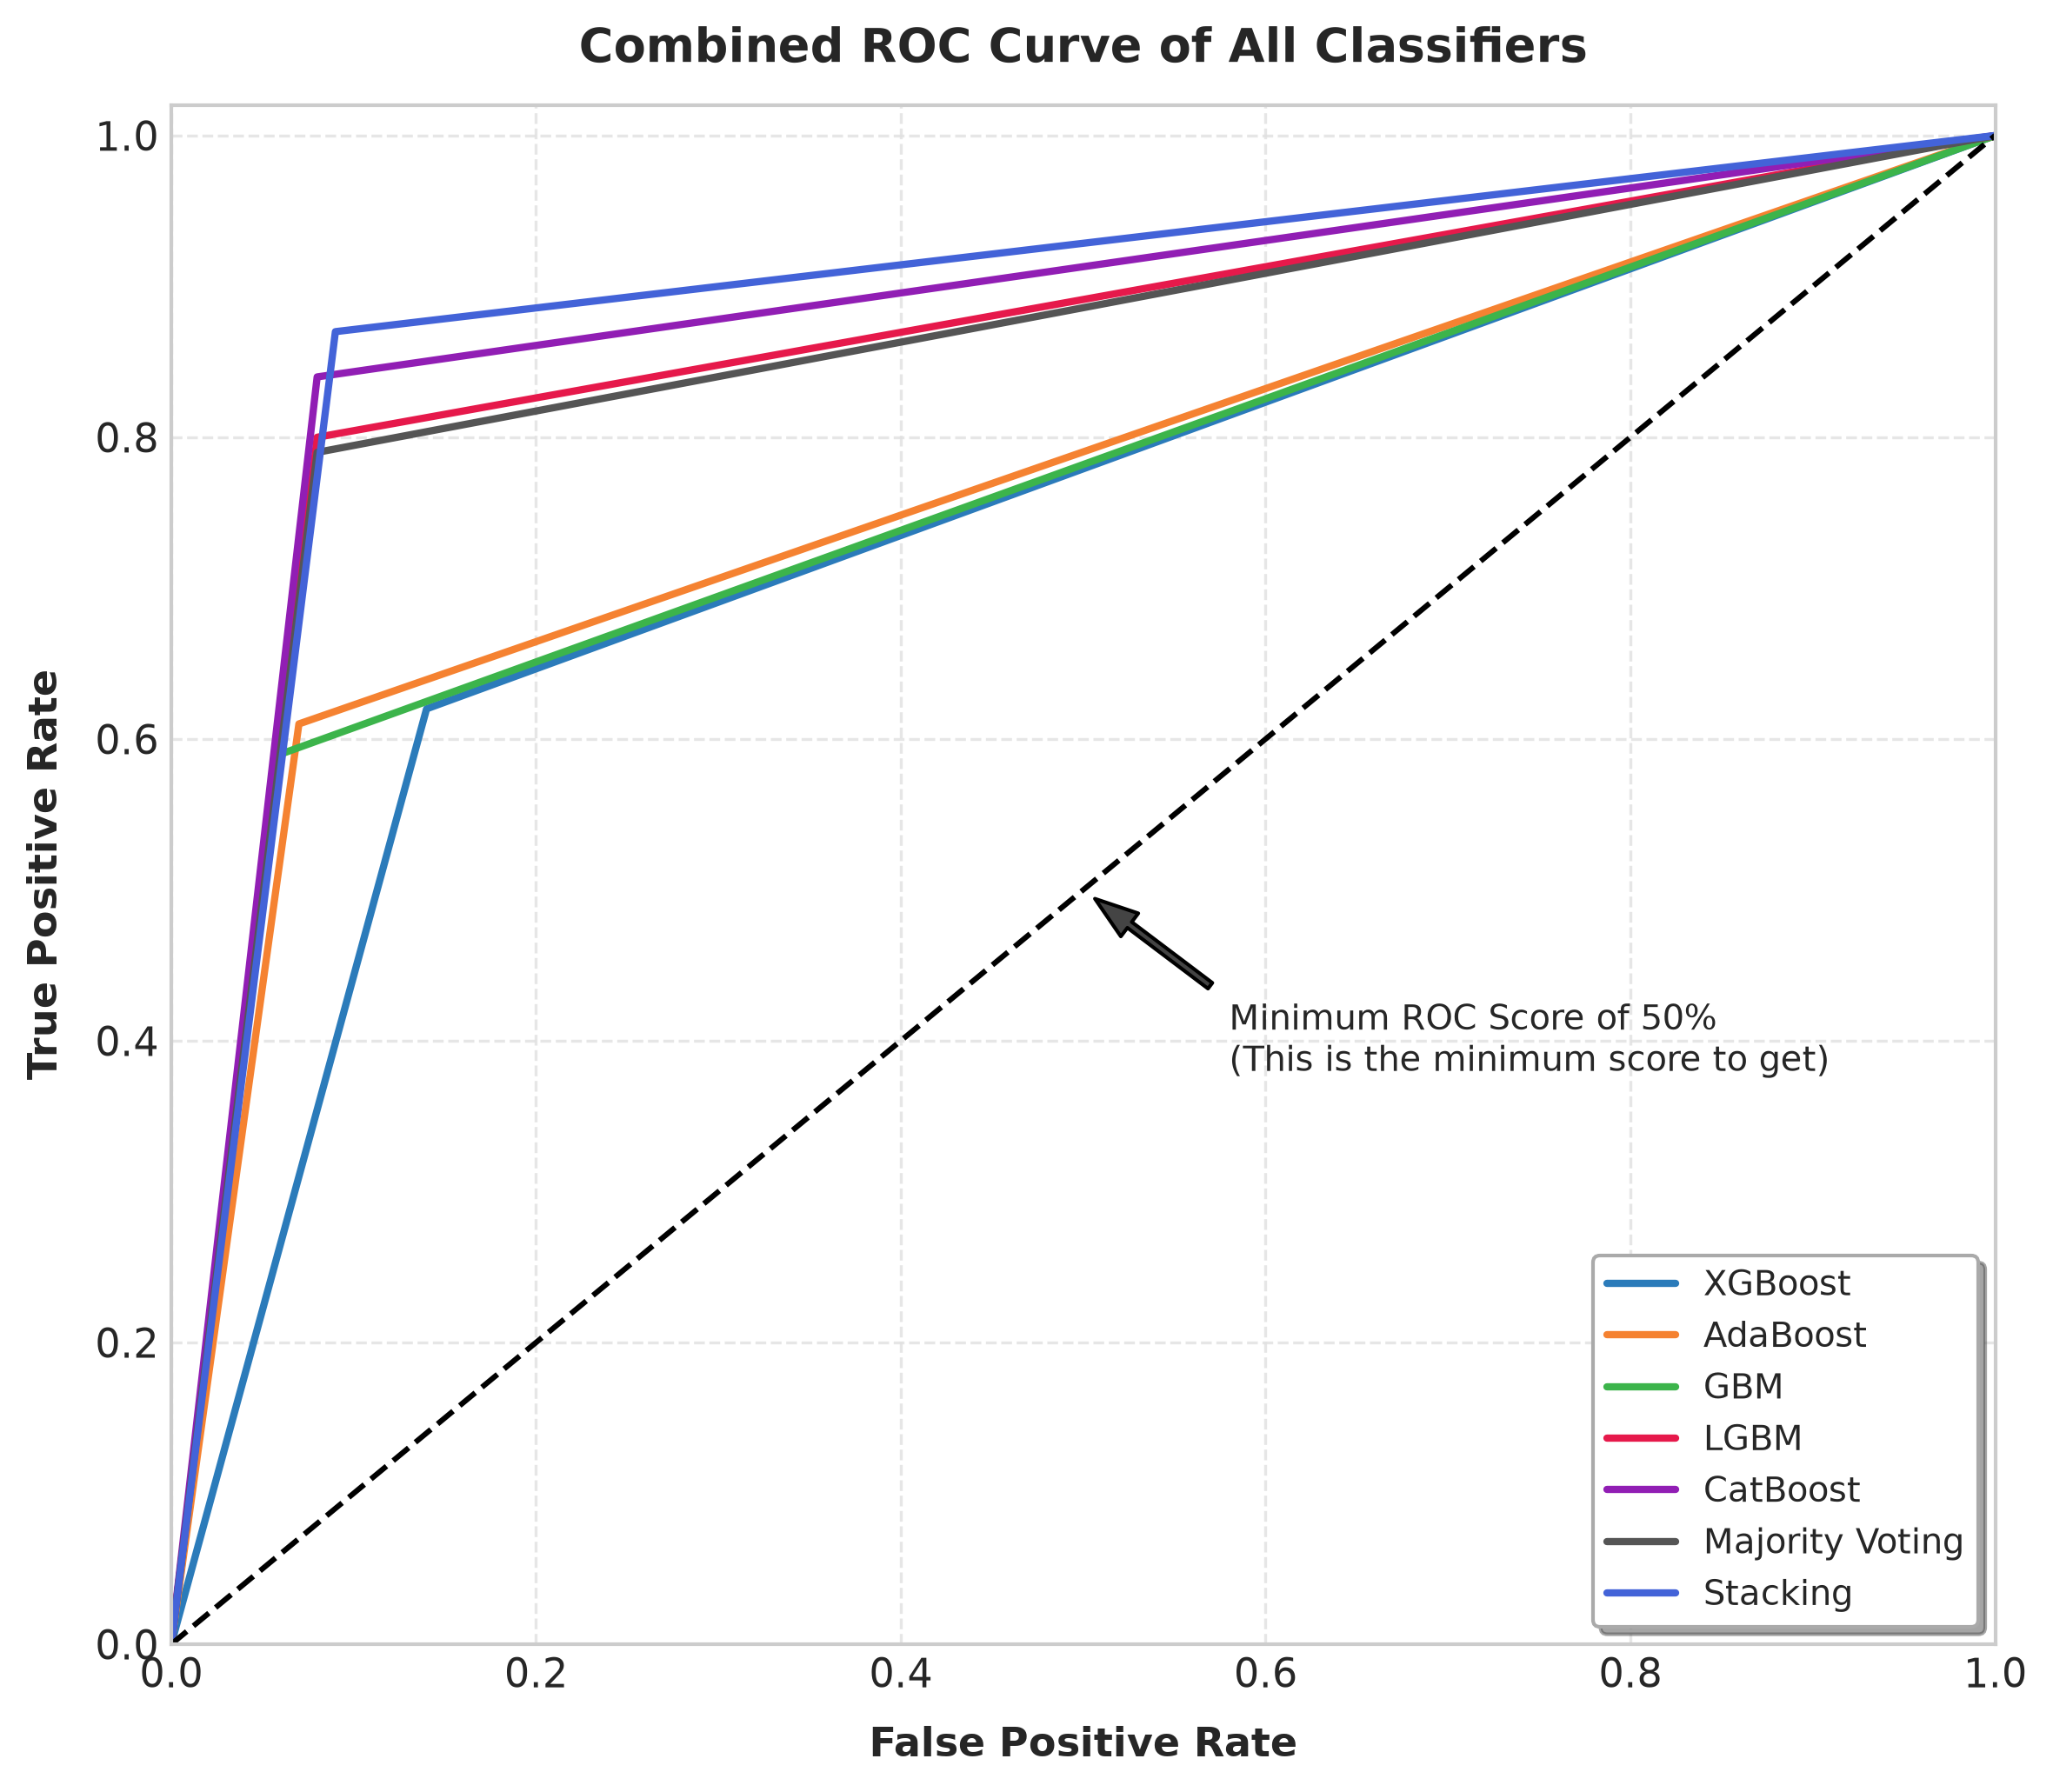

In [7]:
import matplotlib.pyplot as plt 
import numpy as np 

# Set publication-style aesthetics 
plt.rcParams['font.family'] = 'DejaVu Sans' 
plt.rcParams['font.size'] = 11 

# UPDATED DATA FROM TABLE
# Classifier: [Accuracy, Precision, Recall, F-measure, FPR, FNR] 
data = { 
    'AdaBoost':        [76.30, 79.80, 76.50, 75.92, 0.07, 0.39], 
    'XGBoost':         [74.63, 74.67, 73.03, 72.67, 0.14, 0.38], 
    'GBM':             [76.00, 79.25, 75.40, 74.66, 0.06, 0.41], 
    'LGBM':            [86.65, 85.74, 85.14, 85.10, 0.08, 0.20], 
    'CatBoost':        [89.65, 87.65, 87.39, 87.38, 0.08, 0.16], 
    'Majority Voting': [86.78, 85.70, 85.03, 84.98, 0.08, 0.21], 
    'Stacking':        [90.58, 88.67, 88.57, 88.57, 0.09, 0.13] 
} 

classifiers = list(data.keys()) 
accuracy   = [data[c][0] for c in classifiers] 
precision  = [data[c][1] for c in classifiers] 
recall     = [data[c][2] for c in classifiers] 
f_measure  = [data[c][3] for c in classifiers] 

# =============================================================
# 1. PERFORMANCE COMPARISON OF CLASSIFIERS
# =============================================================
fig5, ax5 = plt.subplots(figsize=(10, 6), dpi=300) 

ax5.plot(classifiers, accuracy,  color='#1f77b4', marker='o', linewidth=2.0, markersize=6, label='Accuracy') 
ax5.plot(classifiers, precision, color='#d62728', marker='s', linewidth=2.0, markersize=6, label='Precision') 
ax5.plot(classifiers, recall,    color='#2ca02c', marker='^', linewidth=2.0, markersize=6, label='Recall') 
ax5.plot(classifiers, f_measure, color='#555555', marker='x', linestyle='--', linewidth=1.8, markersize=6, label='F-Measure') 

ax5.set_title('Performance Comparison of Classifiers', fontsize=13, fontweight='bold', pad=12) 
ax5.set_xlabel('Classifier', fontsize=11, fontweight='bold', labelpad=10) 
ax5.set_ylabel('Performance (%)', fontsize=11, fontweight='bold', labelpad=10) 
ax5.set_ylim(70.0, 95.0) 
ax5.set_yticks(np.arange(70.0, 95.5, 2.5)) 
ax5.grid(True, linestyle='--', color='#e0e0e0', alpha=0.8) 

legend5 = ax5.legend(loc='lower right', frameon=True, shadow=True, fancybox=True, fontsize=10) 
legend5.get_frame().set_edgecolor('#aaaaaa') 
plt.tight_layout() 
plt.savefig('Fig5_Performance_Comparison.png', dpi=300) 
plt.show() 

# =============================================================
# 2. COMBINED ROC CURVE OF ALL CLASSIFIERS
# =============================================================
def get_discrete_roc(fpr, fnr): 
    tpr = 1.0 - fnr 
    return [0.0, fpr, 1.0], [0.0, tpr, 1.0] 

fig_roc, ax_roc = plt.subplots(figsize=(8, 7), dpi=300) 

roc_colors = { 
    'XGBoost':         '#2b7bba', 
    'AdaBoost':        '#f58231', 
    'GBM':             '#3cb44b', 
    'LGBM':            '#e6194b', 
    'CatBoost':        '#911eb4', 
    'Majority Voting': '#555555', 
    'Stacking':        '#4363d8' 
} 

order = [ 
    ('XGBoost',         data['XGBoost'][4],         data['XGBoost'][5]), 
    ('AdaBoost',        data['AdaBoost'][4],        data['AdaBoost'][5]), 
    ('GBM',             data['GBM'][4],             data['GBM'][5]), 
    ('LGBM',            data['LGBM'][4],            data['LGBM'][5]), 
    ('CatBoost',        data['CatBoost'][4],        data['CatBoost'][5]), 
    ('Majority Voting', data['Majority Voting'][4], data['Majority Voting'][5]), 
    ('Stacking',        data['Stacking'][4],        data['Stacking'][5]) 
] 

for label, fpr, fnr in order: 
    x_pts, y_pts = get_discrete_roc(fpr, fnr) 
    ax_roc.plot(x_pts, y_pts, color=roc_colors[label], linewidth=2.0, label=label) 

ax_roc.plot([0.0, 1.0], [0.0, 1.0], color='black', linestyle='--', linewidth=1.5) 

ax_roc.annotate( 
    'Minimum ROC Score of 50%\n(This is the minimum score to get)', 
    xy=(0.50, 0.50), xytext=(0.58, 0.38), 
    arrowprops=dict(facecolor='#444444', shrink=0.08, width=2.0, headwidth=8.0), 
    fontsize=9.5 
) 

ax_roc.set_title('Combined ROC Curve of All Classifiers', fontsize=13, fontweight='bold', pad=12) 
ax_roc.set_xlabel('False Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax_roc.set_ylabel('True Positive Rate', fontsize=11, fontweight='bold', labelpad=8) 
ax_roc.set_xlim(0.0, 1.0) 
ax_roc.set_ylim(0.0, 1.02) 
ax_roc.grid(True, linestyle='--', color='#e0e0e0', alpha=0.8) 

legend_roc = ax_roc.legend(loc='lower right', frameon=True, shadow=True, fancybox=True, fontsize=9.5) 
legend_roc.get_frame().set_edgecolor('#aaaaaa') 

plt.tight_layout() 
plt.savefig('Combined_ROC_Curve.png', dpi=300) 
plt.show()